# Simulação EON com NetworkX e Simpy

In [13]:
import matplotlib.pyplot as plt 
import networkx as nx 
import simpy

from IPython.display import Image, display

## Topologia e requisições

O grafo em losango oferece duas rotas entre **A** e **D**. Os pesos são custos abstratos usados só para ordenar as rotas: primeiro `A–B–D`, depois `A–C–D`. Cada enlace tem seis slots de espectro, inicialmente livres.

In [ ]:
# parâmetros da rede de simulação
N_SLOTS = 6

rede = nx.Graph()
enlaces = [
    ('A', 'B', 1.0),
    ('B', 'D', 1.0),
    ('A', 'C', 1.2),
    ('C', 'D', 1.2),
]

In [ ]:
# montando o grafo de rota formado pelos enlaces
for origem, destino, peso in enlaces:
    rede.add_edge(
        origem,
        destino,
        peso=peso,
        ocupacao=[None] * N_SLOTS,
    )

In [ ]:
# lista de dicionários com as requisições feitas
requisicoes = [
    {"id": "R1", "chegada": 0.0, "origem": "A", "destino": "D", "slots": 4, "duracao": 5.0},
    {"id": "R2", "chegada": 0.5, "origem": "A", "destino": "D", "slots": 4, "duracao": 5.5},
    {"id": "R3", "chegada": 1.0, "origem": "A", "destino": "D", "slots": 3, "duracao": 2.0},
    {"id": "R4", "chegada": 2.0, "origem": "A", "destino": "D", "slots": 2, "duracao": 1.5},
]

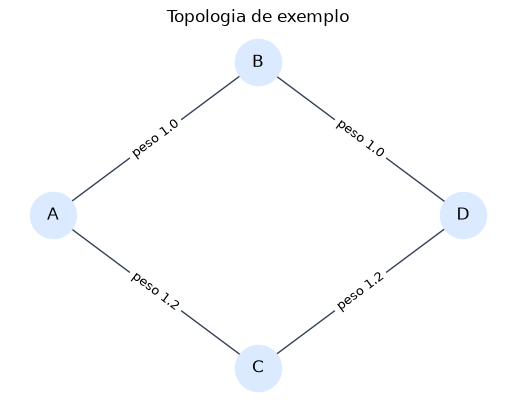

In [ ]:
# plotagem da rede para simulação 
posicoes = {"A": (0, 1), "B": (1, 2), "C": (1, 0), "D": (2, 1)}
rotulos_enlaces = {
    (origem, destino): f"peso {float(dados.get('peso', 0)):.1f}"
    for origem, destino, dados in rede.edges(data=True)
}

nx.draw_networkx(
    rede,
    pos=posicoes,
    node_color="#dbeafe",
    edge_color="#334155",
    node_size=1100,
    font_size=12,
)

nx.draw_networkx_edge_labels(rede, posicoes, edge_labels=rotulos_enlaces, font_size=9)
plt.title("Topologia de exemplo")
plt.axis("off")
plt.show()

## Roteamento e alocação *first-fit*

Para cada requisição, o código tenta os caminhos simples em ordem crescente de custo. Em cada caminho, procura o primeiro bloco contíguo de slots que esteja livre **em todos os enlaces da rota**. Se nenhum caminho comportar a demanda, ela é bloqueada.

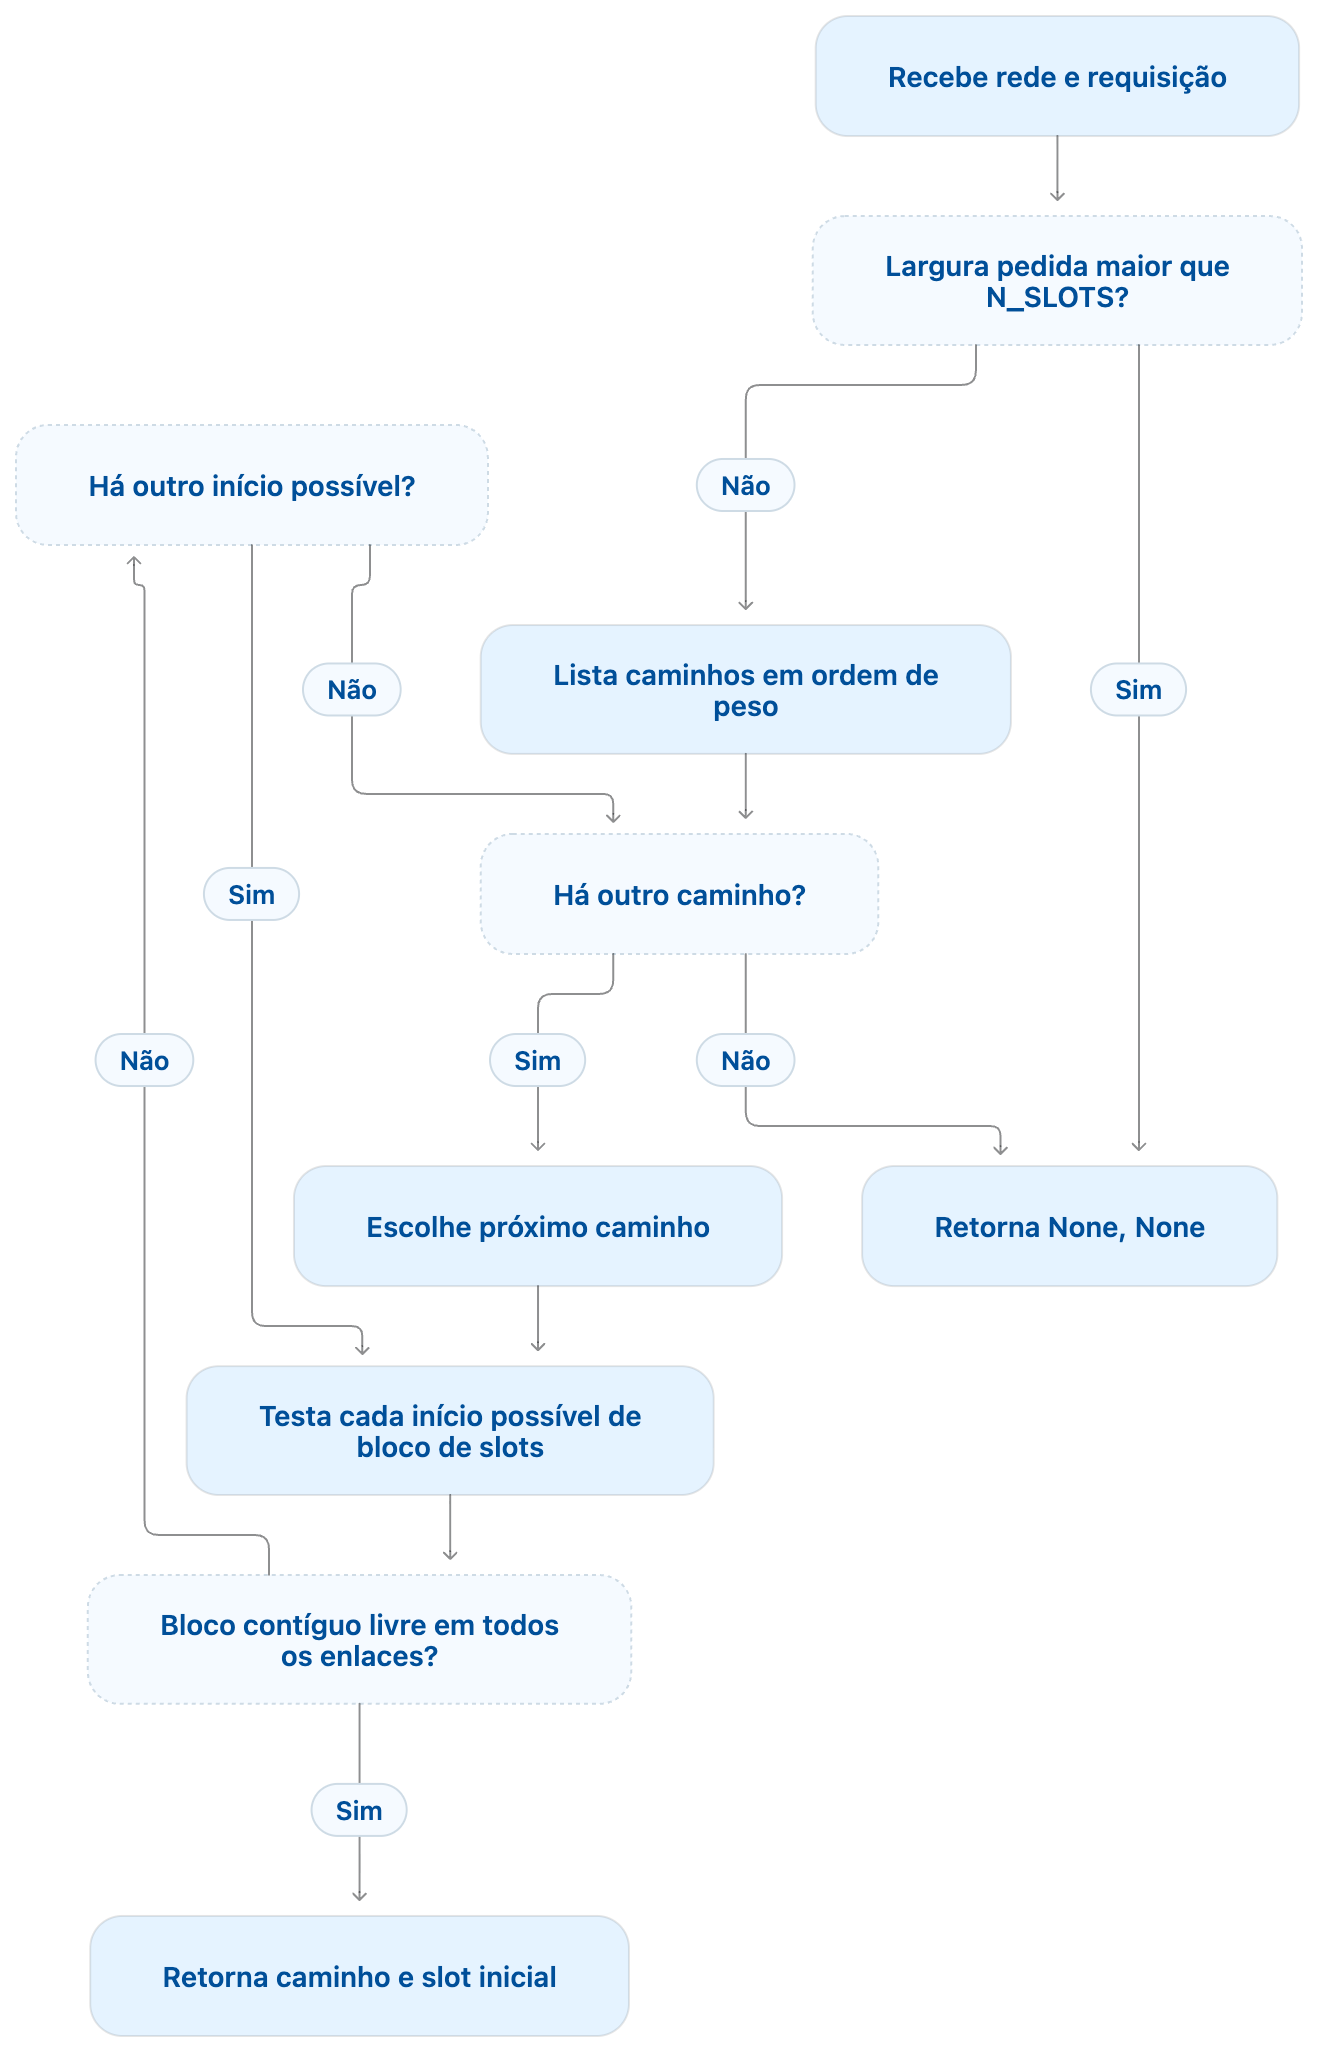

In [ ]:
image_path = "assets/encontrar_rota_e_slots.png"
display(Image(filename=image_path, width=500))

In [12]:
def encontrar_rota_e_slots(rede, requisicao):
    largura = requisicao["slots"]
    if largura > N_SLOTS:
        return None, None

    try:
        caminhos = nx.shortest_simple_paths(
            rede,
            requisicao["origem"],
            requisicao["destino"],
            weight="peso",
        )
        for caminho in caminhos:
            enlaces_caminho = list(zip(caminho[:-1], caminho[1:]))

            for inicio in range(N_SLOTS - largura + 1):
                fim = inicio + largura
                bloco_livre = all(
                    all(rede[u][v]["ocupacao"][inicio:fim][i] is None
                        for i in range(largura))
                    for u, v in enlaces_caminho
                )
                if bloco_livre:
                    return caminho, inicio
    except nx.NetworkXNoPath:
        pass

    return None, None

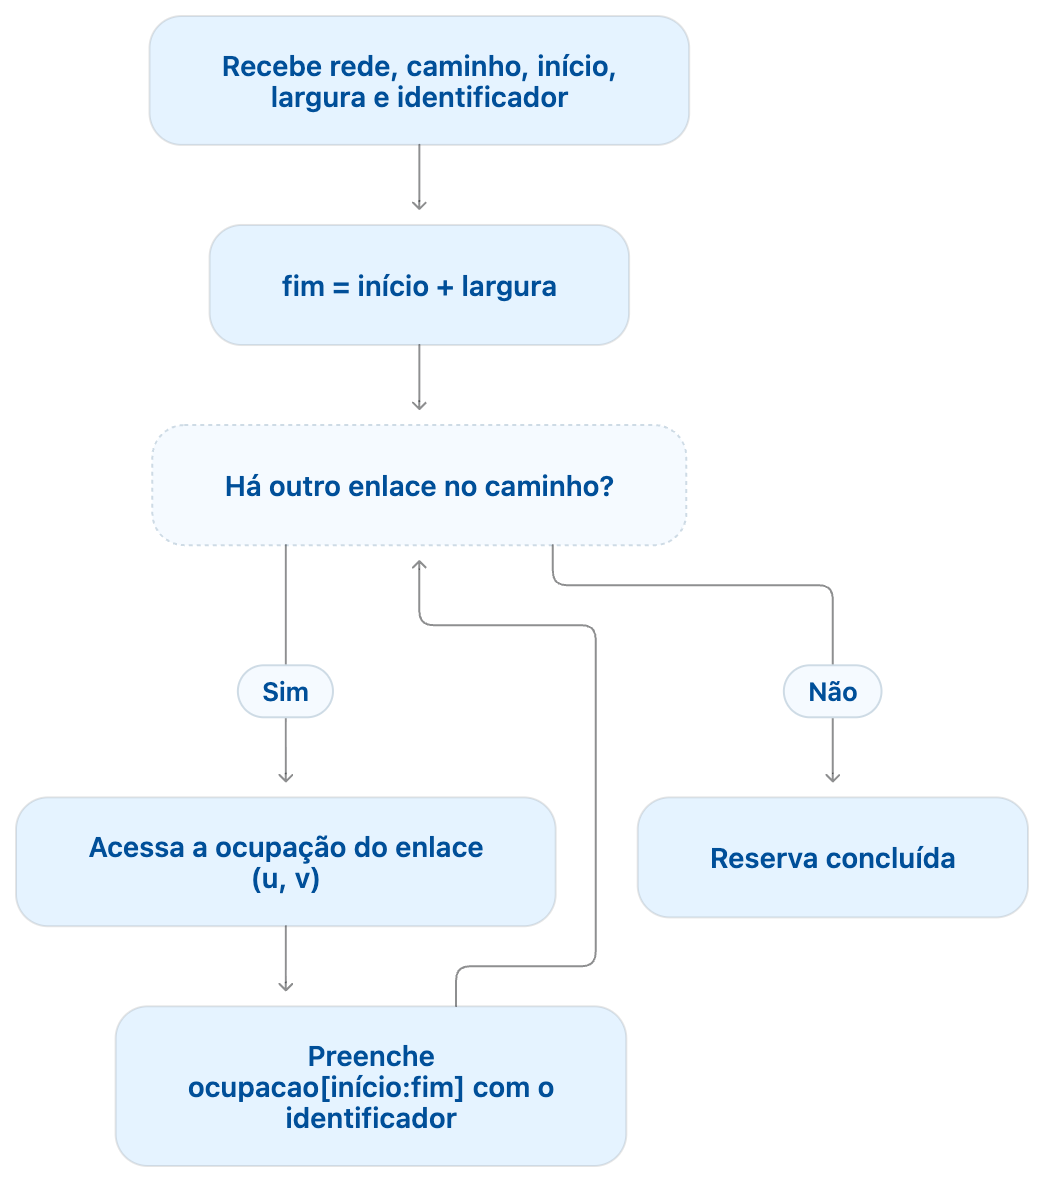

In [16]:
image_path = "assets/reservar_slots.png"
display(Image(filename=image_path, width=500))

In [ ]:
def reservar_slots(rede, caminho, inicio, largura, identificador):
    fim = inicio + largura
    for u, v in zip(caminho[:-1], caminho[1:]):
        rede[u][v]["ocupacao"][inicio:fim] = [identificador] * largura

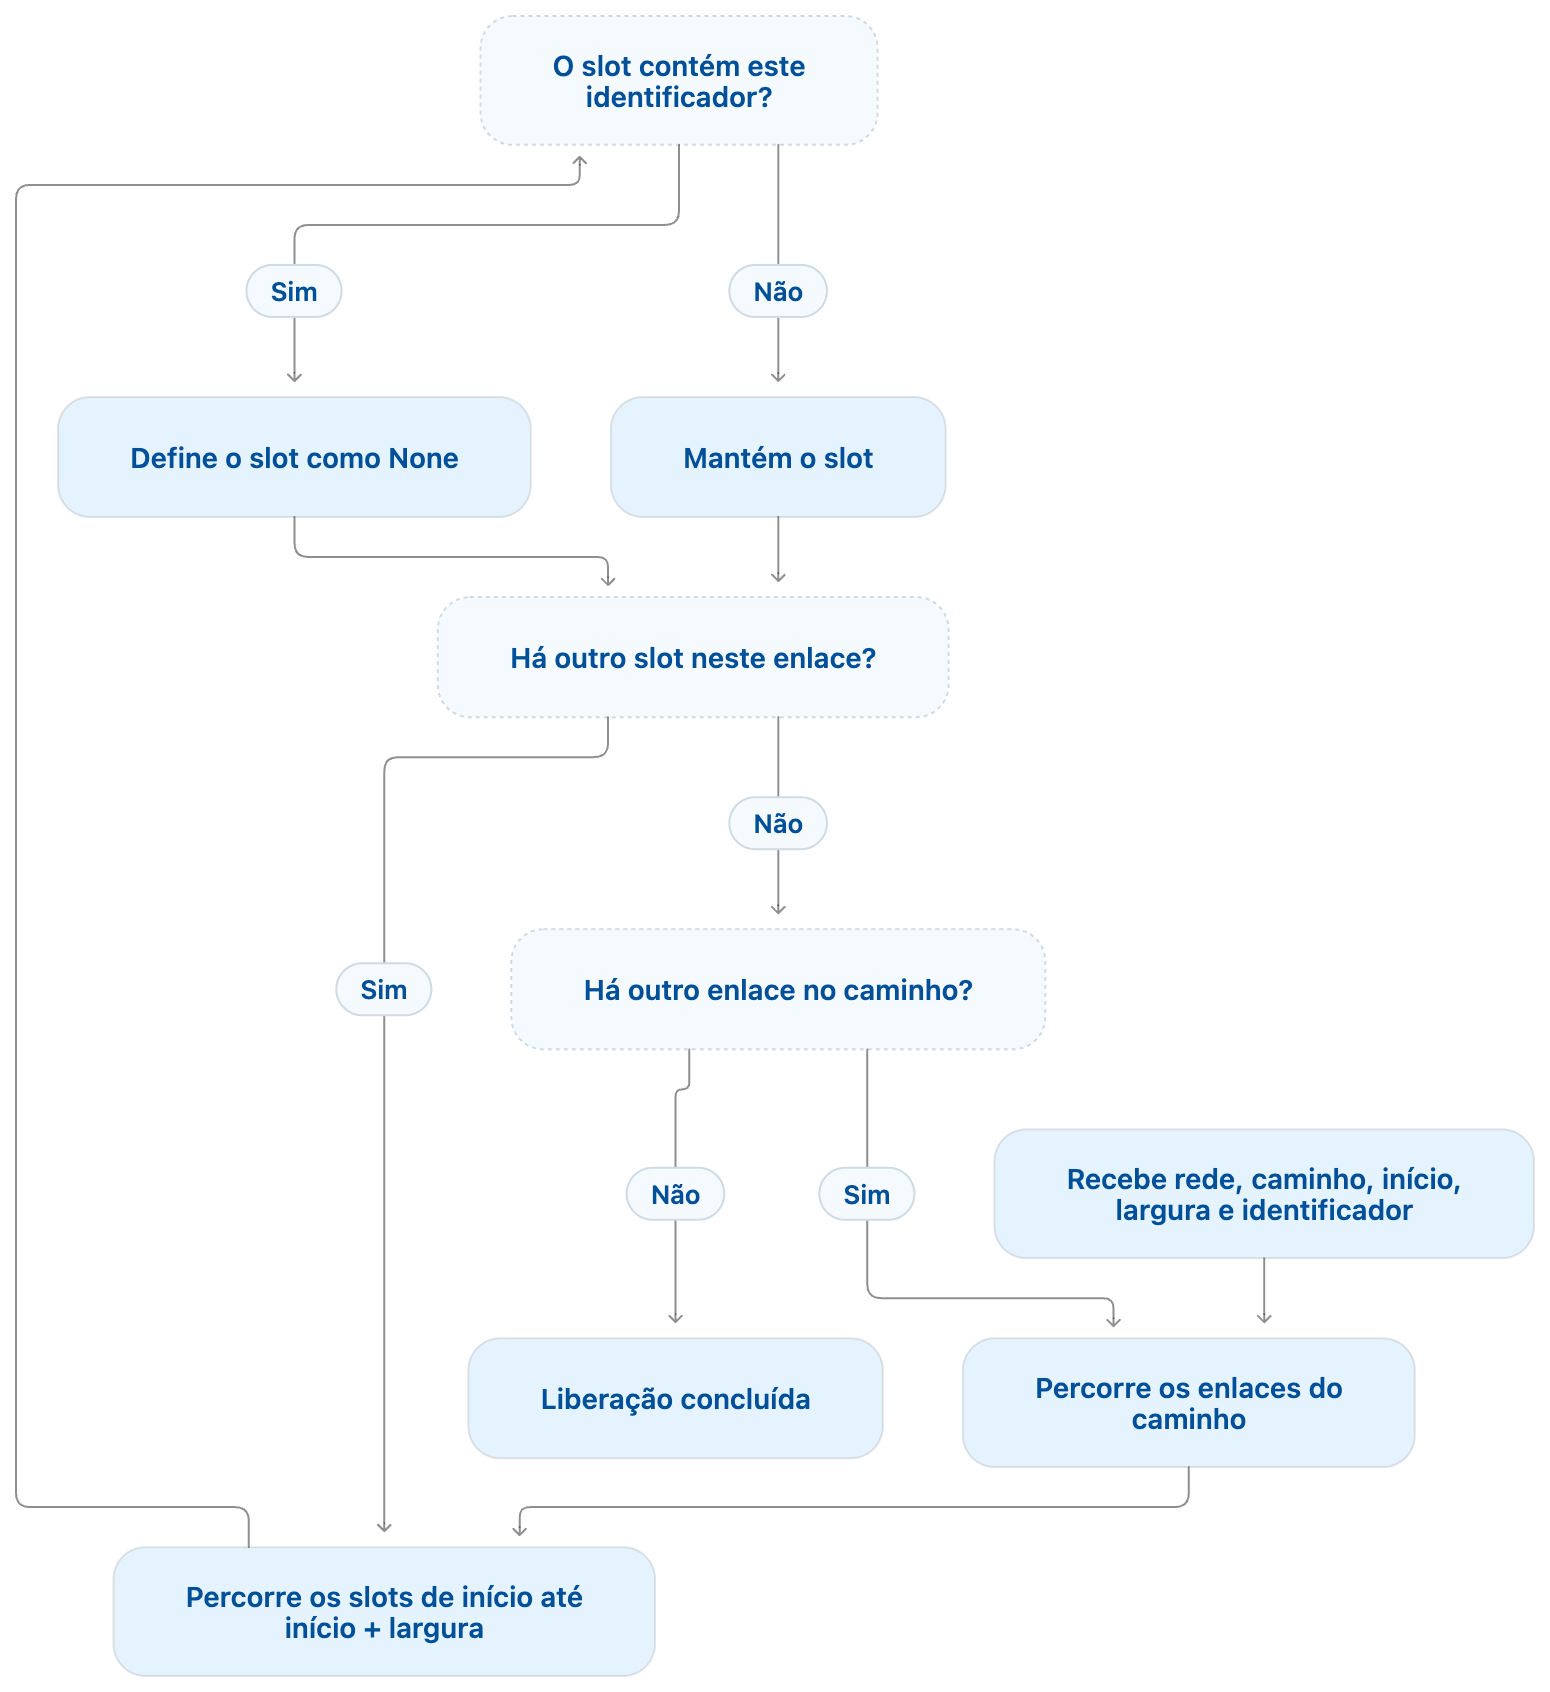

In [17]:
image_path = "assets/liberar_slots.png"
display(Image(filename=image_path, width=500))

In [ ]:
def liberar_slots(rede, caminho, inicio, largura, identificador):
    for u, v in zip(caminho[:-1], caminho[1:]):
        ocupacao = rede[u][v]["ocupacao"]
        for slot in range(inicio, inicio + largura):
            if ocupacao[slot] == identificador:
                ocupacao[slot] = None

## Eventos com Simpy

Cada requisição é um processo. Ele espera até o instante de chegada, tenta reservar recursos e, se for aceita, espera pela duração da conexão antes de liberar os slots. Enquanto isso, o SimPy avança o relógio da simulação e executa os outros processos.

A execução será pausada em `t = 2.1` para guardar uma fotografia da ocupação enquanto há conexões ativas, depois continuará até todas serem liberadas.

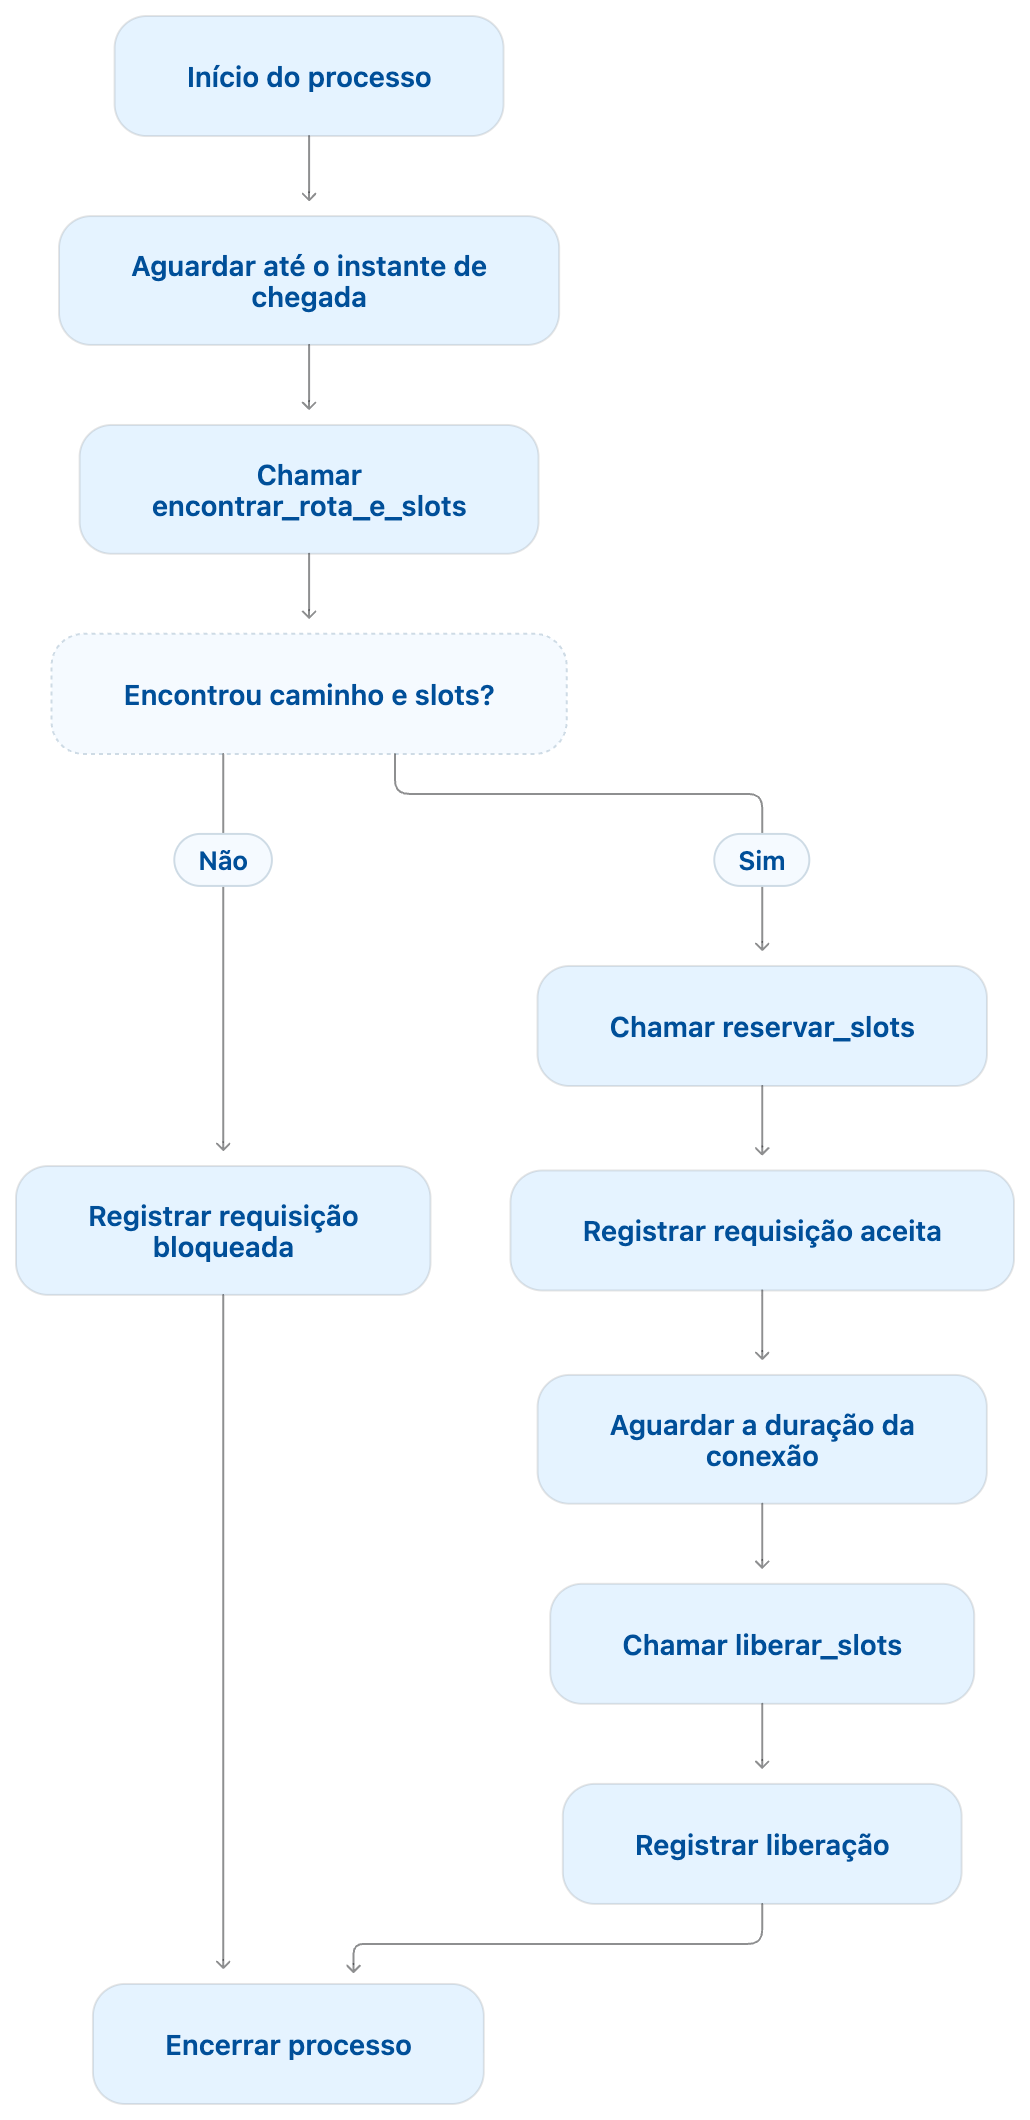

In [18]:
image_path = "assets/processar_requisicao.png"
display(Image(filename=image_path, width=500))

In [ ]:
eventos = []
aceitas = []
bloqueadas = []

def processar_requisicao(env, requisicao):
    yield env.timeout(requisicao["chegada"])

    caminho, inicio = encontrar_rota_e_slots(rede, requisicao)
    identificador = requisicao["id"]

    if caminho is None:
        bloqueadas.append(identificador)
        eventos.append(
            f"t={env.now:>4.1f}: {identificador} bloqueada — sem bloco contíguo disponível"
        )
        return

    largura = requisicao["slots"]
    reservar_slots(rede, caminho, inicio, largura, identificador)
    aceitas.append(identificador)
    intervalo = f"slots {inicio + 1}–{inicio + largura}"
    eventos.append(
        f"t={env.now:>4.1f}: {identificador} aceita em {'–'.join(caminho)}, {intervalo}"
    )

    yield env.timeout(requisicao["duracao"])
    liberar_slots(rede, caminho, inicio, largura, identificador)
    eventos.append(f"t={env.now:>4.1f}: {identificador} liberada")


env = simpy.Environment()
for requisicao in requisicoes:
    env.process(processar_requisicao(env, requisicao))

env.run(until=2.1)
tempo_fotografia = env.now
ocupacao_fotografia = {
    f"{u}–{v}": dados["ocupacao"].copy()
    for u, v, dados in rede.edges(data=True)
}

env.run()

print("Registro de eventos:")
for evento in eventos:
    print(evento)

probabilidade_bloqueio = len(bloqueadas) / len(requisicoes)
print(f"\nBloqueios nesta sequência: {len(bloqueadas)} de {len(requisicoes)} "
      f"({probabilidade_bloqueio:.0%})")

Registro de eventos:
t= 0.0: R1 aceita em A–B–D, slots 1–4
t= 0.5: R2 aceita em A–C–D, slots 1–4
t= 1.0: R3 bloqueada — sem bloco contíguo disponível
t= 2.0: R4 aceita em A–B–D, slots 5–6
t= 3.5: R4 liberada
t= 5.0: R1 liberada
t= 6.0: R2 liberada

Bloqueios nesta sequência: 1 de 4 (25%)


## Ler a ocupação dos slots

O mapa abaixo mostra o estado salvo em `t = 2.1`, antes das liberações. Cada célula representa um slot de um enlace, a identificação da requisição indica quem está usando aquele recurso.

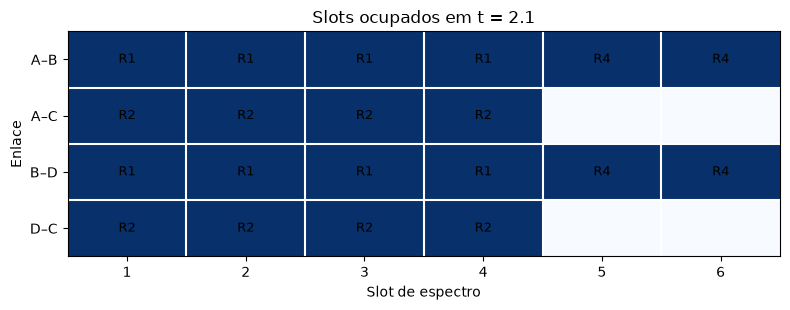

In [9]:
nomes_enlaces = list(ocupacao_fotografia.keys())
matriz_ocupacao = [
    [0 if identificador is None else 1 for identificador in ocupacao_fotografia[enlace]]
    for enlace in nomes_enlaces
]

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.imshow(
    matriz_ocupacao,
    aspect="auto",
    interpolation="none",
    cmap="Blues",
    vmin=0,
    vmax=1,
)

ax.set_title(f"Slots ocupados em t = {tempo_fotografia:.1f}")
ax.set_xlabel("Slot de espectro")
ax.set_ylabel("Enlace")
ax.set_xticks(range(N_SLOTS))
ax.set_xticklabels(range(1, N_SLOTS + 1))
ax.set_yticks(range(len(nomes_enlaces)))
ax.set_yticklabels(nomes_enlaces)

for linha, enlace in enumerate(nomes_enlaces):
    for coluna, identificador in enumerate(ocupacao_fotografia[enlace]):
        if identificador is not None:
            ax.text(coluna, linha, identificador, ha="center", va="center", fontsize=9)

ax.set_xticks([x - 0.5 for x in range(1, N_SLOTS)], minor=True)
ax.set_yticks([y - 0.5 for y in range(1, len(nomes_enlaces))], minor=True)
ax.grid(which="minor", color="white", linewidth=1.5)
ax.tick_params(which="minor", bottom=False, left=False)
fig.tight_layout()
plt.show()